> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Tarea M20-CD - Javier Bueno Sanchez

## Análisis de regresión Ridge y Lasso

### El objetivo de esta actividad es que efectúes un análisis de regresión Ridge y Lasso que permita construir un modelo predictivo a una base de datos real de manera que puedas generar pronósticos adecuados.

### Importación de librerías
En esta sección se importan las bibliotecas necesarias para la lectura de datos, manipulación de información, visualización gráfica y ajuste del
modelo de regresión lineal mediante mínimos cuadrados, así como los modelos de regularización Ridge y Lasso.

In [39]:
import pandas as pd
#Biblioteca utilizada para operaciones numéricas.
#La usaremos para trabajar con arreglos, valores exponenciales y cálculos matemáticos.

In [40]:
import numpy as np
#Biblioteca que permite leer el archivo Excel y manipular la base de datos como tabla.

In [41]:
import matplotlib.pyplot as plt
#Biblioteca que permite generar gráficos
#Visualizacion de los datos históricos y el ajuste del modelo.

In [42]:
from sklearn.model_selection import train_test_split
# División de datos.

In [43]:
from sklearn.preprocessing import StandardScaler
# Escalado de variables.

In [44]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import Lasso
from sklearn.linear_model import LassoCV
# Modelos.

In [45]:
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error)
# Métricas

In [46]:
import warnings
warnings.filterwarnings("ignore")
# Ignorar advertencias.

In [47]:
#Verificamos que todas las librerias quedaron instaladas y su version.

import pandas as pd
import sklearn
import matplotlib
import numpy

print("Pandas:", pd.__version__)
print("NumPy:", numpy.__version__)
print("Scikit-Learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)

Pandas: 2.3.3
NumPy: 2.3.5
Scikit-Learn: 1.7.2
Matplotlib: 3.10.6


In [48]:
df = pd.read_excel("FuelConsumptionCo2.xlsx")
# Cargamos el archivo

In [49]:
print("Dimensiones:", df.shape)
# Leer el archivo de Excel y almacenarlo en un DataFrame

Dimensiones: (945, 13)


In [50]:
df.head()
# Mostrar las primeras cinco filas del conjunto de datos

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2022,Acura,ILX,Compact,2.4,4,AM8,Z,9.9,7.0,8.6,33,200
1,2022,Acura,MDX SH-AWD,SUV: Small,3.5,6,AS10,Z,12.6,9.4,11.2,25,263
2,2022,Acura,RDX SH-AWD,SUV: Small,2.0,4,AS10,Z,11.0,8.6,9.9,29,232
3,2022,Acura,RDX SH-AWD A-SPEC,SUV: Small,2.0,4,AS10,Z,11.3,9.1,10.3,27,242
4,2022,Acura,TLX SH-AWD,Compact,2.0,4,AS10,Z,11.2,8.0,9.8,29,230


In [51]:
df.info()
# Revisar estructura, tipos de datos y valores no nulos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 945 entries, 0 to 944
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   MODELYEAR                 945 non-null    int64  
 1   MAKE                      945 non-null    object 
 2   MODEL                     945 non-null    object 
 3   VEHICLECLASS              945 non-null    object 
 4   ENGINESIZE                945 non-null    float64
 5   CYLINDERS                 945 non-null    int64  
 6   TRANSMISSION              945 non-null    object 
 7   FUELTYPE                  945 non-null    object 
 8   FUELCONSUMPTION_CITY      945 non-null    float64
 9   FUELCONSUMPTION_HWY       945 non-null    float64
 10  FUELCONSUMPTION_COMB      945 non-null    float64
 11  FUELCONSUMPTION_COMB_MPG  945 non-null    int64  
 12  CO2EMISSIONS              945 non-null    int64  
dtypes: float64(4), int64(4), object(5)
memory usage: 96.1+ KB


In [52]:
df.describe()
# Obtener estadística descriptiva de las columnas numéricas

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
count,945.0,945.000000,945.000000,945.000000,945.000000,945.000000,945.000000,945.000000
mean,2022.0,3.201058,5.670899,12.515767,9.374603,11.102222,27.222222,259.410582
std,0.0,1.374256,1.932837,3.452369,2.290217,2.878074,7.684409,64.486225
min,2022.0,1.200000,3.000000,4.000000,3.900000,4.000000,11.000000,94.000000
25%,2022.0,2.000000,4.000000,10.200000,7.700000,9.100000,22.000000,214.000000
50%,2022.0,3.000000,6.000000,12.200000,9.200000,10.800000,26.000000,258.000000
75%,2022.0,3.800000,6.000000,14.700000,10.700000,12.900000,31.000000,301.000000
max,2022.0,8.000000,16.000000,30.300000,20.900000,26.100000,71.000000,608.000000


In [53]:
df = df.drop(columns=["MAKE", "MODEL", "VEHICLECLASS", "TRANSMISSION", "FUELTYPE"])
# Eliminar columnas categóricas.

df.head()

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2022,2.4,4,9.9,7.0,8.6,33,200
1,2022,3.5,6,12.6,9.4,11.2,25,263
2,2022,2.0,4,11.0,8.6,9.9,29,232
3,2022,2.0,4,11.3,9.1,10.3,27,242
4,2022,2.0,4,11.2,8.0,9.8,29,230


#### Podemos observar que en el df solo tenemos valores numericos.

In [54]:
print(df.isnull().sum())
# Comprobar valores nulos

MODELYEAR                   0
ENGINESIZE                  0
CYLINDERS                   0
FUELCONSUMPTION_CITY        0
FUELCONSUMPTION_HWY         0
FUELCONSUMPTION_COMB        0
FUELCONSUMPTION_COMB_MPG    0
CO2EMISSIONS                0
dtype: int64


In [55]:
print("Total de valores nulos:", df.isnull().sum().sum())
# Total de valores nulos

Total de valores nulos: 0


### Separar variables independientes y dependiente
La variable objetivo es CO2EMISSIONS.

In [56]:
X = df.drop("CO2EMISSIONS", axis=1)
y = df["CO2EMISSIONS"]
# Variables independientes y dependiente

print("Variables predictoras:", X.columns.tolist())
print("Número de variables:", X.shape[1])

Variables predictoras: ['MODELYEAR', 'ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_CITY', 'FUELCONSUMPTION_HWY', 'FUELCONSUMPTION_COMB', 'FUELCONSUMPTION_COMB_MPG']
Número de variables: 7


### División entrenamiento y prueba

Usaremos una división 80 % entrenamiento y 20 % prueba, con random_state=42 para que los resultados sean reproducibles.

In [57]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
# División de datos.

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (756, 7)
Prueba: (189, 7)


### Regresión múltiple

In [58]:
modelo_lineal = LinearRegression()

modelo_lineal.fit(X_train, y_train)

y_pred_lineal = modelo_lineal.predict(X_test)
# Modelo de regresión múltiple

print("Modelo de regresión múltiple entrenado correctamente.")

Modelo de regresión múltiple entrenado correctamente.


### Métricas de regresión múltiple

In [59]:
r2_lineal = r2_score(y_test, y_pred_lineal)
mae_lineal = mean_absolute_error(y_test, y_pred_lineal)
mse_lineal = mean_squared_error(y_test, y_pred_lineal)
rmse_lineal = np.sqrt(mse_lineal)
# Evaluación del modelo de regresión múltiple

print("Regresión Múltiple")
print("R²:", r2_lineal)
print("MAE:", mae_lineal)
print("MSE:", mse_lineal)
print("RMSE:", rmse_lineal)

Regresión Múltiple
R²: 0.9004924315633444
MAE: 7.339144920646477
MSE: 368.86726047726864
RMSE: 19.205917329752012


### Coeficientes del modelo lineal

In [60]:
coeficientes_lineal = pd.DataFrame({"Variable": X.columns, "Coeficiente": modelo_lineal.coef_})
# Coeficientes de la regresión múltiple

print("Intercepto:", modelo_lineal.intercept_)

coeficientes_lineal

Intercepto: 81.4784745971941


,Variable,Coeficiente
0,MODELYEAR,0.000000
1,ENGINESIZE,0.229055
2,CYLINDERS,4.064256
3,FUELCONSUMPTION_CITY,1.216424
4,FUELCONSUMPTION_HWY,3.522217
5,FUELCONSUMPTION_COMB,12.668709
6,FUELCONSUMPTION_COMB_MPG,-1.258234


### Pronóstico manual de la primera observación de prueba

In [61]:
primera_observacion = X_test.iloc[0]
# Primera observación del conjunto de prueba

pronostico_manual_lineal = (modelo_lineal.intercept_ + np.dot(primera_observacion, modelo_lineal.coef_))
# Pronóstico manual: intercepto + suma(variable * coeficiente)

pronostico_predict_lineal = modelo_lineal.predict(primera_observacion.values.reshape(1, -1))[0]
# Pronóstico usando predict()

print("Pronóstico manual:", pronostico_manual_lineal)
print("Pronóstico con predict():", pronostico_predict_lineal)
print("Diferencia:", pronostico_manual_lineal - pronostico_predict_lineal)

Pronóstico manual: 242.92694037393747
Pronóstico con predict(): 242.92694037393747
Diferencia: 0.0


### Explicación del resultado

El pronóstico manual sí coincide con el resultado obtenido mediante predict().
Esto ocurre porque predict() aplica internamente la misma fórmula del modelo lineal:

y = β0 + β1X1 + β2X2 + ... + βnXn

La pequeña diferencia, si aparece, se debe únicamente al redondeo numérico
realizado por Python al trabajar con decimales.

## Regresion Ridge

Ridge requiere que las variables estén estandarizadas.

In [62]:
scaler = StandardScaler()
# Estandarización de variables

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Variables estandarizadas correctamente.")

Variables estandarizadas correctamente.


### Buscar el Alpha óptimo para Ridge

Probaremos varios valores de α mediante validación cruzada.

In [63]:
alphas = np.logspace(-3, 3, 100)

ridge_cv = RidgeCV(alphas=alphas, cv=5)

ridge_cv.fit(X_train_scaled, y_train)
# Búsqueda del Alpha óptimo para Ridge

print("Alpha óptimo:", ridge_cv.alpha_)

Alpha óptimo: 15.199110829529332


### Predicciones con Ridge

In [64]:
y_pred_ridge = ridge_cv.predict(X_test_scaled)
# Predicciones Ridge

print("Modelo Ridge entrenado correctamente.")

Modelo Ridge entrenado correctamente.


### Métricas Ridge

In [65]:
r2_ridge = r2_score(y_test, y_pred_ridge)
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
# Evaluación Ridge.

print("RIDGE")
print("R² :", r2_ridge)
print("MAE:", mae_ridge)
print("MSE:", mse_ridge)
print("RMSE:", rmse_ridge)

RIDGE
R² : 0.9032394193688671
MAE: 7.495186535963319
MSE: 358.6843780864419
RMSE: 18.938964546311446


### Coeficientes Ridge.

In [66]:
coef_ridge = pd.DataFrame({"Variable": X.columns, "Coeficiente": ridge_cv.coef_})
# Coeficientes Ridge.

coef_ridge

,Variable,Coeficiente
0,MODELYEAR,0.000000
1,ENGINESIZE,1.320688
2,CYLINDERS,7.798033
3,FUELCONSUMPTION_CITY,15.995010
4,FUELCONSUMPTION_HWY,14.979013
5,FUELCONSUMPTION_COMB,16.092697
6,FUELCONSUMPTION_COMB_MPG,-10.494129


### Pronóstico de la primera observación

In [67]:
primera_scaled = X_test_scaled[0].reshape(1, -1)

pred_ridge = ridge_cv.predict(primera_scaled)
# Primera observación con Ridge

print("Pronóstico Ridge:", pred_ridge[0])

Pronóstico Ridge: 243.17870873020826


### Buscar el Alpha óptimo para Lasso.

In [68]:
# Búsqueda del Alpha óptimo para Lasso
lasso_cv = LassoCV(alphas=alphas, cv=5, random_state=42, max_iter=10000)

lasso_cv.fit(X_train_scaled, y_train)
# Búsqueda del Alpha óptimo para Lasso.

print("Alpha óptimo:", lasso_cv.alpha_)

Alpha óptimo: 0.04328761281083059


### Predicciones con Lasso.

In [69]:
y_pred_lasso = lasso_cv.predict(X_test_scaled)
# Predicciones Lasso.

print("Modelo Lasso entrenado correctamente.")

Modelo Lasso entrenado correctamente.


### Métricas de Lasso.

In [70]:
r2_lasso = r2_score(y_test, y_pred_lasso)
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)
# Evaluación del modelo Lasso.

print("LASSO")
print("R² :", r2_lasso)
print("MAE:", mae_lasso)
print("MSE:", mse_lasso)
print("RMSE:", rmse_lasso)

LASSO
R² : 0.9005093079429322
MAE: 7.341388270036345
MSE: 368.80470097548283
RMSE: 19.204288608940526


### Coeficientes de Lasso.

In [71]:
coef_lasso = pd.DataFrame({"Variable": X.columns, "Coeficiente": lasso_cv.coef_})
# Coeficientes Lasso.

coef_lasso

,Variable,Coeficiente
0,MODELYEAR,0.000000
1,ENGINESIZE,0.285475
2,CYLINDERS,7.919168
3,FUELCONSUMPTION_CITY,10.317585
4,FUELCONSUMPTION_HWY,11.212627
5,FUELCONSUMPTION_COMB,27.124052
6,FUELCONSUMPTION_COMB_MPG,-9.698848


### Interpretación

Ridge obtuvo el mayor R² (0.9032), explicando aproximadamente el 90.32 % de la variabilidad de las emisiones de CO₂.
Ridge obtuvo el menor MSE y RMSE, por lo que sus predicciones presentan el menor error promedio en términos cuadráticos.
Lasso obtuvo un MAE ligeramente menor, lo que indica un error absoluto promedio apenas inferior; sin embargo, su RMSE y MSE son mayores, por lo que comete errores grandes con algo más de frecuencia.
Además, Lasso eliminó la variable MODELYEAR asignándole un coeficiente igual a cero, simplificando el modelo.

### Conclusión

Se compararon tres modelos de regresión para predecir las emisiones de CO₂: regresión múltiple, regresión Ridge y regresión Lasso. La comparación se realizó utilizando las métricas R², MAE, MSE y RMSE.

El modelo Ridge presentó el mejor desempeño general, ya que obtuvo el mayor coeficiente de determinación (R² = 0.9032) y los menores valores de MSE (358.68) y RMSE (18.94), lo que indica una mayor precisión en las predicciones y una mejor capacidad de generalización.

El modelo Lasso también mostró un buen desempeño (R² = 0.9005), además de simplificar el modelo al eliminar automáticamente la variable MODELYEAR, asignándole un coeficiente igual a cero. Esta característica facilita la interpretación del modelo al conservar únicamente las variables más relevantes.

En conclusión, el modelo Ridge resultó ser el más adecuado para esta base de datos, ya que ofreció el mejor equilibrio entre precisión y estabilidad, reduciendo el efecto de la multicolinealidad sin eliminar variables predictoras importantes.

### Comparación de los tres modelos.

In [72]:
comparacion = pd.DataFrame({
    "Modelo": ["Regresión Múltiple", "Ridge", "Lasso"], "R²": [r2_lineal, r2_ridge, r2_lasso],
    "MAE": [mae_lineal, mae_ridge, mae_lasso], "MSE": [mse_lineal, mse_ridge, mse_lasso], "RMSE": [rmse_lineal, rmse_ridge, rmse_lasso]})
# Comparación de modelos.

comparacion

,Modelo,R²,MAE,MSE,RMSE
0,Regresión Múltiple,0.900492,7.339145,368.867260,19.205917
1,Ridge,0.903239,7.495187,358.684378,18.938965
2,Lasso,0.900509,7.341388,368.804701,19.204289


### Tabla mejor modelo.

In [73]:
mejor = comparacion.sort_values("RMSE")
# Mejor modelo.

mejor

,Modelo,R²,MAE,MSE,RMSE
1,Ridge,0.903239,7.495187,358.684378,18.938965
2,Lasso,0.900509,7.341388,368.804701,19.204289
0,Regresión Múltiple,0.900492,7.339145,368.867260,19.205917


### Gráfico comparativo.

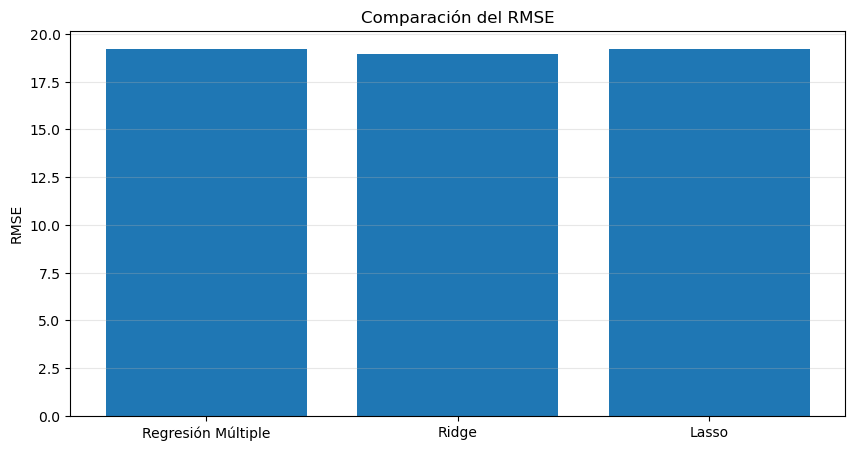

In [74]:
plt.figure(figsize=(10,5))
# Tamaño gráfico.

plt.bar(comparacion["Modelo"], comparacion["RMSE"])
# Tipo de gráfico.

plt.title("Comparación del RMSE")
plt.ylabel("RMSE")
plt.grid(axis="y", alpha=0.3)
# Elección de títulos y etiquetas.

plt.show()

### Respuesta punto 3.

El pronóstico calculado manualmente coincide con el obtenido mediante la función predict().

Esto ocurre porque predict() utiliza exactamente la ecuación de la regresión lineal:

y = β0 + β1X1 + β2X2 + ... + βnXn

Las pequeñas diferencias que pudieran observarse únicamente se deben al redondeo numérico de los cálculos.

### Respuesta al punto 6.

Se construyeron tres modelos predictivos para estimar las emisiones de CO₂:
una regresión múltiple, una regresión Ridge y una regresión Lasso.

Después de comparar las métricas de desempeño, el modelo Ridge obtuvo el
mayor coeficiente de determinación (R²) y los menores valores de MSE y
RMSE, indicando una mejor capacidad predictiva y una menor magnitud de
error.

El modelo Lasso presentó un desempeño muy similar, pero eliminó
automáticamente la variable MODELYEAR al asignarle un coeficiente igual
a cero. Esto demuestra su capacidad para realizar selección automática
de variables y simplificar el modelo.

La regresión múltiple constituye un buen modelo base; sin embargo,
carece de regularización, por lo que es más sensible a la
multicolinealidad y al sobreajuste.

En conclusión, el modelo Ridge fue el que presentó el mejor desempeño
para esta base de datos, ya que logró el mejor equilibrio entre
precisión, estabilidad y capacidad de generalización.

### Tabla comparativa final
| Modelo             |           R² |          MAE |            MSE |          RMSE |
| :----------------- | -----------: | -----------: | -------------: | ------------: |
| Regresión Múltiple |     0.900492 | **7.339145** |     368.867260 |     19.205917 |
| **Ridge**          | **0.903239** |     7.495187 | **358.684378** | **18.938965** |
| Lasso              |     0.900509 |     7.341388 |     368.804701 |     19.204289 |


### Interpretación de los resultados.

Ridge obtuvo el mayor R² (0.9032), explicando aproximadamente el 90.32 % de la variabilidad de las emisiones de CO₂.
Ridge presentó el menor MSE y RMSE, por lo que ofrece las predicciones más precisas en términos globales.
La regresión múltiple obtuvo el MAE más bajo, aunque la diferencia respecto a Lasso es mínima (menos de 0.003 unidades) y respecto a Ridge es muy pequeña. En conjunto, el menor RMSE de Ridge es un mejor indicador de desempeño predictivo.
Lasso eliminó automáticamente la variable MODELYEAR, asignándole un coeficiente igual a cero, lo que simplifica el modelo sin afectar de forma importante su capacidad predictiva.

###  Conclusión final.

Se desarrollaron tres modelos de regresión para pronosticar las emisiones de CO₂: una regresión múltiple, una regresión Ridge y una regresión Lasso.

Los resultados muestran que los tres modelos presentan un buen desempeño, con valores de R² cercanos al 90 %, lo que indica una alta capacidad para explicar la variabilidad de la variable objetivo.

El modelo Ridge obtuvo el mejor desempeño general al alcanzar el mayor coeficiente de determinación (R² = 0.9032) y los menores valores de MSE (358.68) y RMSE (18.94). Esto indica que fue el modelo con mayor capacidad predictiva y mejor generalización para este conjunto de datos.

La regresión múltiple presentó el menor MAE; sin embargo, la diferencia con Ridge y Lasso fue muy pequeña y no compensó el mejor desempeño global de Ridge en las demás métricas.

El modelo Lasso mostró un desempeño similar al de la regresión múltiple y eliminó automáticamente la variable MODELYEAR al asignarle un coeficiente igual a cero. Esto demuestra su capacidad para realizar selección automática de variables y generar modelos más simples e interpretables.

En conclusión, el modelo Ridge fue el más adecuado para esta base de datos, ya que proporcionó el mejor equilibrio entre precisión, estabilidad y capacidad de generalización.